In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from feature_engine.encoding import CountFrequencyEncoder
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
import shap
# import mlflow.sklearn
# import mlflow
import os
import joblib
import json

import config

In [2]:
# # define Mlflow env. settings
# mlflow.set_tracking_uri(uri=config.mlflow_uri)
# %env MLFLOW_TRACKING_URI= config.mlflow_db
# %env mlflow_tracking_username = config.mlflow_un
# %env mlflow_tracking_password = config.mlflow_pw
# #mlflow.enable_system_metrics_logging()
# #mlflow.autolog(log_models=True, log_datasets=True)

In [3]:
def list_folders(path):
    """Lists all folders in the given directory."""

    folders = []
    for entry in os.listdir(path):
        if os.path.isdir(os.path.join(path, entry)):
            folders.append(entry)
    return folders

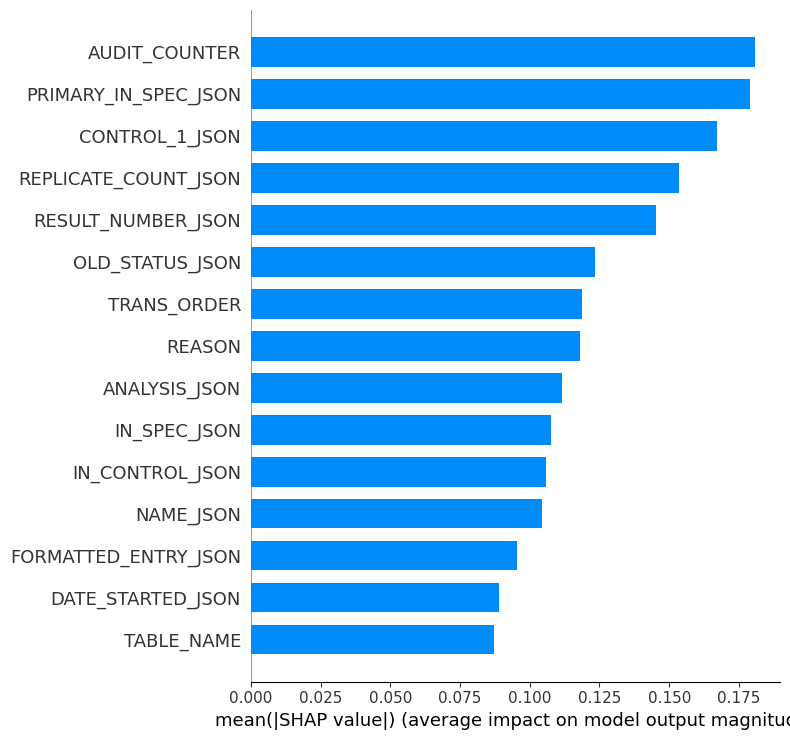

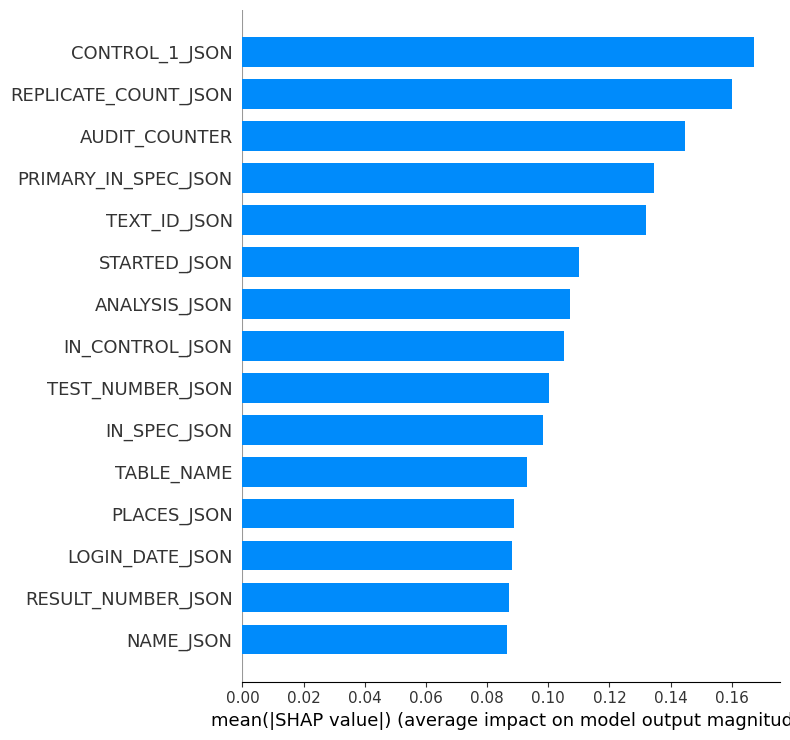

Error - Feature store file not found. Check directory.
Error - Feature store file not found. Check directory.


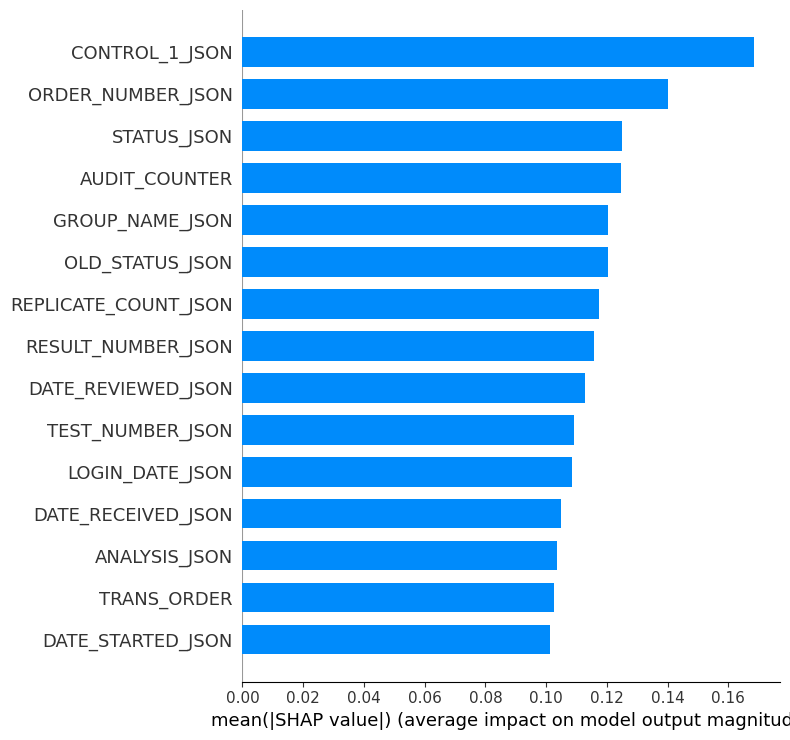

No anomalies for Sample ModifySample Default


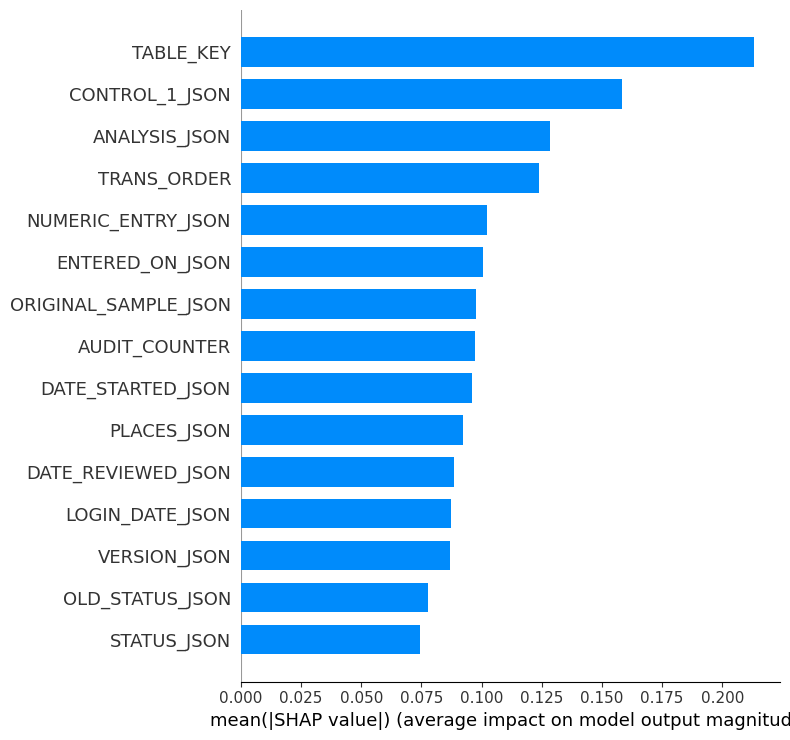

In [4]:
# mlflow.set_experiment("T0083 - Audit Review") 
# with mlflow.start_run(run_name=f"Sklearn-IF Model", nested=True) as greatgrandparent_run:
for customer in config.customerList: 
    for auditLog in config.auditList:  
        FilterTypeList = list_folders(f'{config.data_location}FS_audit_type_table_name/{auditLog}/') 
        for FilterType in FilterTypeList:
            # with mlflow.start_run(run_name=f"Audit Type context-{auditLog}-{customer}", nested=True) as grandparent_run:
                filepath = Path(f'{config.data_location}FS_audit_type_table_name/{auditLog}/{FilterType}/FS_audit_type_table_name_{auditLog}_{FilterType}_{customer}.parquet') 
                if filepath.is_file()==True:
                    dataFrame = pd.read_parquet(filepath, engine='pyarrow')
                    dataFrame = dataFrame.astype(str)
                    features = dataFrame.columns.tolist()
                    categoricalColumns = dataFrame.select_dtypes(include=['object']).columns.tolist()
                    encoder = CountFrequencyEncoder(encoding_method='frequency', variables=categoricalColumns, ignore_format=True)
                    train, test = train_test_split(dataFrame,test_size=0.30)
                    enc_train = encoder.fit_transform(train) #Troubleshooting
                    enc_test = encoder.fit_transform(test)

                    # Define model parameters
                    numTrees = 100
                    #sampleSize = 256
                    random = np.random.RandomState(1234)

                    # Initialize the model
                    if_model = IsolationForest(random_state=random)  

                    # Start an MLflow run
                    # with mlflow.start_run(run_name=f"Model Evaluation", nested=True) as parent_run:
                    # Log model parameters and train
                    #mlflow.log_param("ntrees", numTrees)
                    #mlflow.log_param("sample_size", sampleSize)
                    if_model.fit(enc_train)        
                    
                    # Predict anomalies and generate histogram
                    predicted = if_model.predict(enc_test)
                    predictedScore = if_model.score_samples(enc_test)            
                    
                    # Combine the scores with the original data
                    predictedDF = pd.concat([pd.DataFrame(data=predicted,columns=['anomaly']),test],axis=1)
                    predictedDF = pd.concat([pd.DataFrame(data=predictedScore,columns=['anomaly_score']),predictedDF],axis=1)
                    predictedDF = predictedDF[predictedDF['anomaly'] > 0]
                    
                    if predictedDF.empty:
                        print(f'No anomalies for {auditLog} {FilterType} {customer}')     
                    else:
                        #Export Dataset
                        #mlflow.log_table(predictedDF,f"{customer}_{FilterType}_testDF.json")                         
                        
                        # with mlflow.start_run(run_name=f"Explain_model", nested=True) as child_run:
                        #Train explaination model
                        explainer = shap.TreeExplainer(if_model, feature_names=if_model.feature_names_in_) 
                        shap_values = explainer.shap_values(enc_train)

                        ## plot generation
                        shapBarplot = plt.figure(figsize=(9, 3))
                        shap.summary_plot(shap_values, features=explainer.feature_names , plot_type="bar", max_display=15)
                        #mlflow.log_figure(shapBarplot, f"{customer}_{FilterType}_GlobalBarPlot.png")  
                        #logModel = mlflow.sklearn.log_model(sk_model=if_model,artifact_path=f"Sklearn-IF_{auditLog}_{FilterType}_{customer}_audit_type_model",registered_model_name=f"Sklearn-IF_{auditLog}_{FilterType}_{customer}_audit_type_model")
                        
                        # Get the absolute mean SHAP values for feature importance
                        mean_abs_shap_values = np.abs(shap_values).mean(axis=0)

                        # Sort features based on their importance
                        sorted_indices = np.argsort(mean_abs_shap_values)[-10:]  # Get indices of top 10 features
                        top_10_shap_values = shap_values[:, sorted_indices]
                        top_10_feature_names = [explainer.feature_names[i] for i in sorted_indices]
                        top_10_mean_shap_values = mean_abs_shap_values[sorted_indices]

                        data = {}
                        for i in range(len(top_10_feature_names)):
                            data[top_10_feature_names[i]] = top_10_mean_shap_values[i]

                        json_data = json.dumps(data)
                        #mlflow.log_table(data,f"Var_Imp_{auditLog}_{FilterType}_{customer}_audit_type_model.json")
                        dirPath = f"{config.model_location}{auditLog}/varimp"
                        Path(dirPath).mkdir(parents=True, exist_ok=True) 
                        with open(f'{dirPath}/Var_Imp_{auditLog}_{FilterType}_{customer}_audit_type_model.json', 'w') as outfile:
                            outfile.write(json_data)  

                        # Export models
                        dirPath = f"{config.model_location}{auditLog}"
                        Path(dirPath).mkdir(parents=True, exist_ok=True) 
                        joblib.dump(if_model,f"{dirPath}/Sklearn-IF_{auditLog}_{FilterType}_{customer}_audit_type_model.pkl")
                        joblib.dump(explainer,f"{dirPath}/Explainer_Sklearn-IF_{auditLog}_{FilterType}_{customer}_audit_type_model.pkl")

                else:
                    print("Error - Feature store file not found. Check directory.")        
                

In [5]:
# import mlflow
# mlflow.end_run()